In [3]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path

dump_dir = Path('.')

X = torch.load(dump_dir / 'feat.pth', map_location='cpu').float()
file_name = torch.load(dump_dir / 'file_name.pth', map_location='cpu')
file_path = torch.load(dump_dir / 'file_path.pth', map_location='cpu')

print(f"Embeddings: {X.shape}, {X.dtype}")
print(f"file_name: {file_name.shape}, {file_name.dtype}")
print(f"file_path: {file_path.shape}, {file_path.dtype}")


Embeddings: torch.Size([354958, 384]), torch.float32
file_name: torch.Size([354958, 34]), torch.float32
file_path: torch.Size([354958, 107]), torch.float32


In [4]:
def decode_ascii_row(row):
    codes = row.round().clamp(0, 255).to(torch.int).tolist()
    return "".join(chr(c) for c in codes)

def decode_filename(row):
    return decode_ascii_row(row).strip("\x00").strip()

def decode_path(row):
    return decode_ascii_row(row).rstrip("~").strip("\x00").strip()

N = X.shape[0]
names = [decode_filename(file_name[i]) for i in range(N)]
paths = [decode_path(file_path[i]) for i in range(N)]
rel_paths = [f"{paths[i]}/{names[i]}" for i in range(N)]

print(f"Total: {N} segments")
print("\nFirst 10:")
for i in range(min(10, N)):
    print(f"{i:04d} -> {rel_paths[i]}")


Total: 354958 segments

First 10:
0000 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch0_0.png/S4A09154_20190218_163000_ch0_0.png
0001 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch0_1.png/S4A09154_20190218_163000_ch0_1.png
0002 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch0_2.png/S4A09154_20190218_163000_ch0_2.png
0003 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch0_3.png/S4A09154_20190218_163000_ch0_3.png
0004 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch0_4.png/S4A09154_20190218_163000_ch0_4.png
0005 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch0_5.png/S4A09154_20190218_163000_ch0_5.png
0006 -> 2019_specs_samples/all_spectrograms/all_spectrograms/S4A09154_20190218_163000_ch1_0.png/S4A09154_20190218_163000_ch1_0.png
0007 -> 2019_specs_samples/all_spectrograms/all_s

In [5]:
df = pd.DataFrame({
    'idx': np.arange(N),
    'path': paths,
    'name': names,
    'relpath': rel_paths
})

print(df.head(20))
print(f"\nShape: {df.shape}")


    idx                                               path  \
0     0  2019_specs_samples/all_spectrograms/all_spectr...   
1     1  2019_specs_samples/all_spectrograms/all_spectr...   
2     2  2019_specs_samples/all_spectrograms/all_spectr...   
3     3  2019_specs_samples/all_spectrograms/all_spectr...   
4     4  2019_specs_samples/all_spectrograms/all_spectr...   
5     5  2019_specs_samples/all_spectrograms/all_spectr...   
6     6  2019_specs_samples/all_spectrograms/all_spectr...   
7     7  2019_specs_samples/all_spectrograms/all_spectr...   
8     8  2019_specs_samples/all_spectrograms/all_spectr...   
9     9  2019_specs_samples/all_spectrograms/all_spectr...   
10   10  2019_specs_samples/all_spectrograms/all_spectr...   
11   11  2019_specs_samples/all_spectrograms/all_spectr...   
12   12  2019_specs_samples/all_spectrograms/all_spectr...   
13   13  2019_specs_samples/all_spectrograms/all_spectr...   
14   14  2019_specs_samples/all_spectrograms/all_spectr...   
15   15 

In [11]:
df = pd.DataFrame({
    'idx': np.arange(N),
    'path': paths,
    'name': names,
    'relpath': rel_paths
})

print(df.head(20))
print(f"\nShape: {df.shape}")

import umap
import matplotlib.pyplot as plt

embeddings = X.numpy()
print(f"Embeddings shape: {embeddings.shape}")

sample_size = min(354958, len(embeddings))
sample_idx = np.random.choice(len(embeddings), sample_size, replace=False)
embeddings_sample = embeddings[sample_idx]

print(f"\nUMAP reduction {embeddings_sample.shape} -> 2D...")
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42, verbose=True)
embeddings_2d = reducer.fit_transform(embeddings_sample)


    idx                                               path  \
0     0  2019_specs_samples/all_spectrograms/all_spectr...   
1     1  2019_specs_samples/all_spectrograms/all_spectr...   
2     2  2019_specs_samples/all_spectrograms/all_spectr...   
3     3  2019_specs_samples/all_spectrograms/all_spectr...   
4     4  2019_specs_samples/all_spectrograms/all_spectr...   
5     5  2019_specs_samples/all_spectrograms/all_spectr...   
6     6  2019_specs_samples/all_spectrograms/all_spectr...   
7     7  2019_specs_samples/all_spectrograms/all_spectr...   
8     8  2019_specs_samples/all_spectrograms/all_spectr...   
9     9  2019_specs_samples/all_spectrograms/all_spectr...   
10   10  2019_specs_samples/all_spectrograms/all_spectr...   
11   11  2019_specs_samples/all_spectrograms/all_spectr...   
12   12  2019_specs_samples/all_spectrograms/all_spectr...   
13   13  2019_specs_samples/all_spectrograms/all_spectr...   
14   14  2019_specs_samples/all_spectrograms/all_spectr...   
15   15 

c:\Users\cheml\anaconda3\envs\remi_tropical\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(angular_rp_forest=True, metric='cosine', n_jobs=1, random_state=42, verbose=True)
Tue Jan 20 15:46:36 2026 Construct fuzzy simplicial set
Tue Jan 20 15:46:37 2026 Finding Nearest Neighbors
Tue Jan 20 15:46:37 2026 Building RP forest with 35 trees
Tue Jan 20 15:47:07 2026 NN descent for 18 iterations
	 1  /  18
	 2  /  18
	Stopping threshold met -- exiting after 2 iterations
Tue Jan 20 15:47:47 2026 Finished Nearest Neighbor Search
Tue Jan 20 15:47:50 2026 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Tue Jan 20 16:00:08 2026 Finished embedding


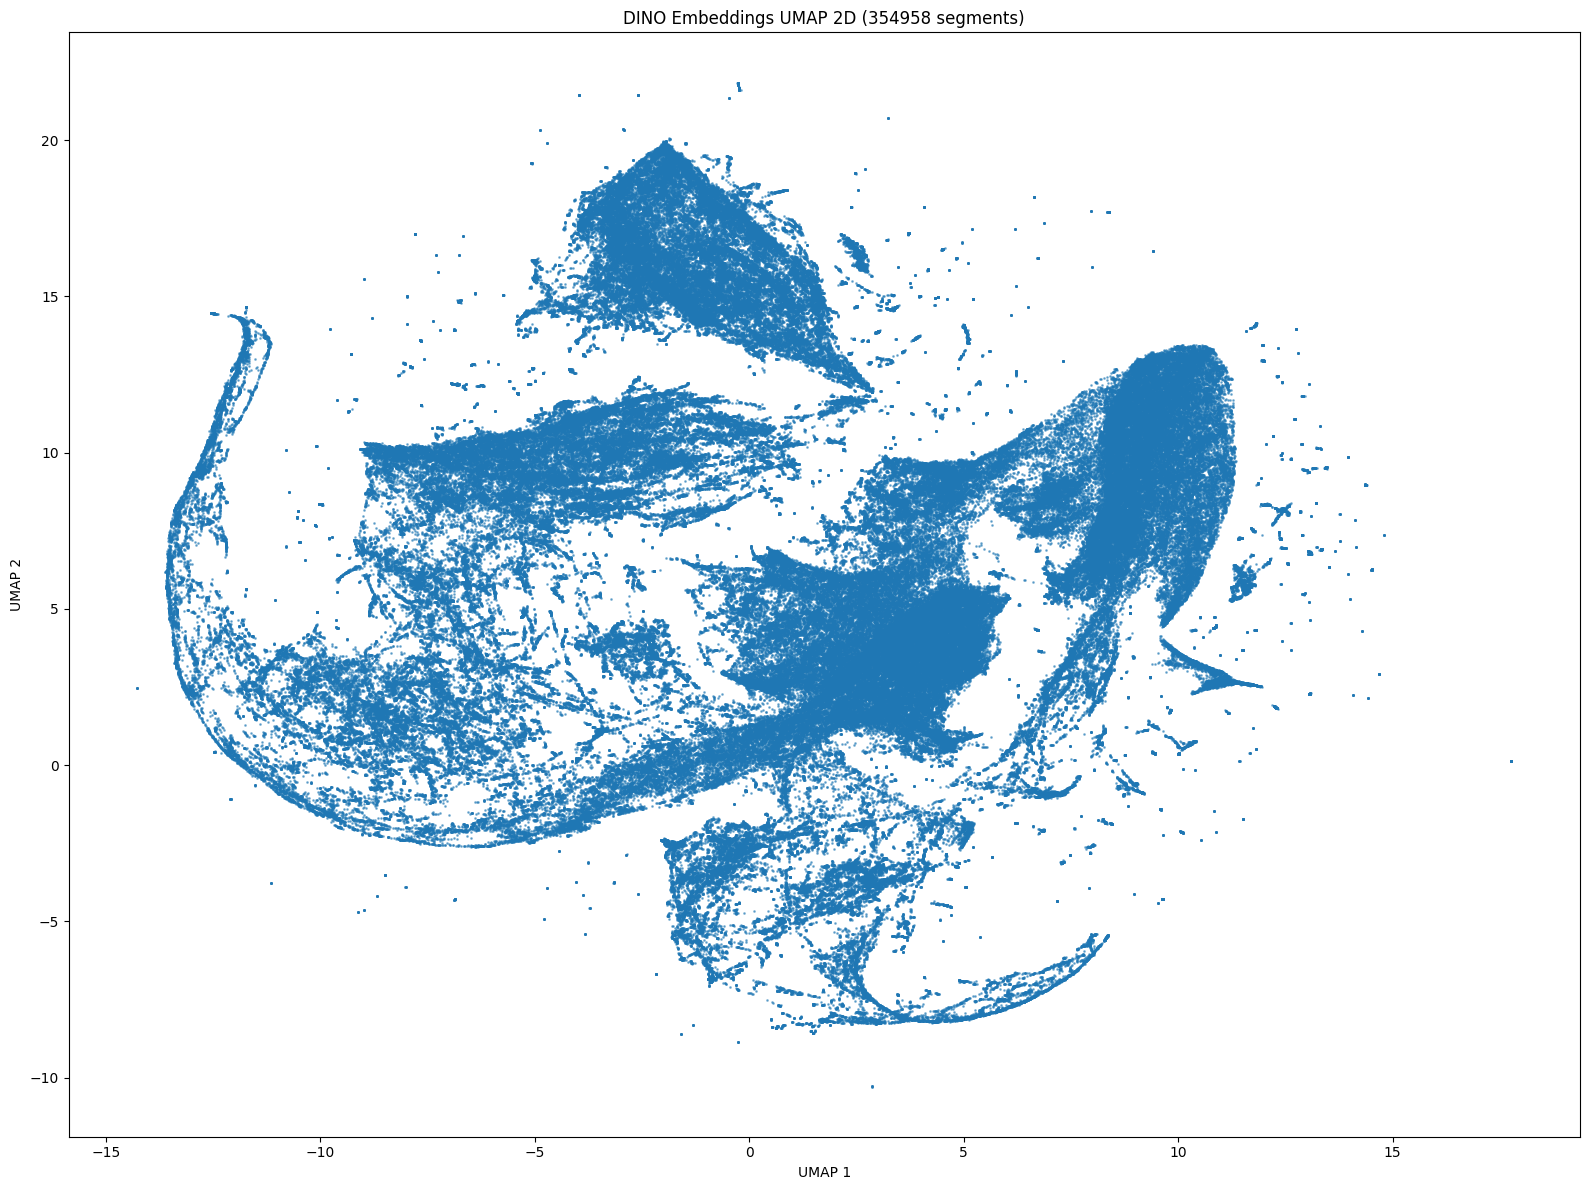

In [12]:
plt.figure(figsize=(16, 12))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], s=1, alpha=0.5)
plt.title(f'DINO Embeddings UMAP 2D ({sample_size} segments)')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.tight_layout()
plt.savefig('dino_umap_2d.png', dpi=150)
plt.show()

In [13]:
torch.save(torch.tensor(embeddings_2d), 'dino_embeddings_2d.pth')
df.to_csv('dino_metadata.csv', index=False)
print("Saved: dino_embeddings_2d.pth, dino_metadata.csv")


Saved: dino_embeddings_2d.pth, dino_metadata.csv


In [15]:
import hdbscan
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

configs = [
    (10, 3, 0.3),
    (15, 5, 0.3),
    (20, 5, 0.2),
    (8, 3, 0.1),
    (12, 4, 0.15),
]

for min_size, min_samp, eps in configs:
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=min_size,
        min_samples=min_samp,
        cluster_selection_epsilon=eps,
        metric='euclidean',
        cluster_selection_method='leaf'
    )
    
    labels = clusterer.fit_predict(embeddings_2d)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    pct_noise = 100 * n_noise / len(labels)
    
    print(f"({min_size:2d}, {min_samp:2d}, {eps:.2f}) -> Clusters: {n_clusters:3d}, Bruit: {pct_noise:5.1f}%")


(10,  3, 0.30) -> Clusters: 160, Bruit:   0.1%
(15,  5, 0.30) -> Clusters: 124, Bruit:   0.1%
(20,  5, 0.20) -> Clusters: 130, Bruit:   0.3%
( 8,  3, 0.10) -> Clusters: 429, Bruit:   0.4%
(12,  4, 0.15) -> Clusters: 253, Bruit:   0.2%


In [22]:
import hdbscan

configs = [
    (30, 10, 0.08),
    (30, 8, 0.1),
    (35, 10, 0.1),
    (30, 12, 0.1),
    (40, 10, 0.1),
    (30, 10, 0.12),
]

for min_size, min_samp, eps in configs:
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=min_size,
        min_samples=min_samp,
        cluster_selection_epsilon=eps,
        metric='euclidean',
        cluster_selection_method='leaf'
    )
    
    labels = clusterer.fit_predict(embeddings_2d)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    pct_noise = 100 * n_noise / len(labels)
    
    print(f"({min_size:2d}, {min_samp:2d}, {eps:.2f}) -> Clusters: {n_clusters:3d}, Bruit: {pct_noise:5.1f}%")


(30, 10, 0.08) -> Clusters: 410, Bruit:   5.2%
(30,  8, 0.10) -> Clusters: 237, Bruit:   2.3%
(35, 10, 0.10) -> Clusters: 227, Bruit:   3.0%
(30, 12, 0.10) -> Clusters: 278, Bruit:   3.6%
(40, 10, 0.10) -> Clusters: 205, Bruit:   3.1%
(30, 10, 0.12) -> Clusters: 184, Bruit:   1.8%


In [23]:
import hdbscan

configs = [
    (30, 10, 0.08),
    (30, 11, 0.08),
    (30, 12, 0.08),
    (32, 10, 0.08),
    (28, 10, 0.08),
    (30, 10, 0.07),
]

for min_size, min_samp, eps in configs:
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=min_size,
        min_samples=min_samp,
        cluster_selection_epsilon=eps,
        metric='euclidean',
        cluster_selection_method='leaf'
    )
    
    labels = clusterer.fit_predict(embeddings_2d)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    pct_noise = 100 * n_noise / len(labels)
    
    print(f"({min_size:2d}, {min_samp:2d}, {eps:.2f}) -> Clusters: {n_clusters:3d}, Bruit: {pct_noise:5.1f}%")


(30, 10, 0.08) -> Clusters: 410, Bruit:   5.2%
(30, 11, 0.08) -> Clusters: 434, Bruit:   6.1%
(30, 12, 0.08) -> Clusters: 449, Bruit:   6.9%
(32, 10, 0.08) -> Clusters: 387, Bruit:   5.3%
(28, 10, 0.08) -> Clusters: 430, Bruit:   5.2%
(30, 10, 0.07) -> Clusters: 537, Bruit:   7.5%


In [24]:
import hdbscan
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

configs = [
    (30, 10, 0.08),
    (30, 11, 0.08),
    (30, 12, 0.08),
    (32, 10, 0.08),
    (28, 10, 0.08),
    (30, 10, 0.07),
]

results = []

for min_size, min_samp, eps in configs:
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=min_size,
        min_samples=min_samp,
        cluster_selection_epsilon=eps,
        metric='euclidean',
        cluster_selection_method='leaf'
    )
    
    labels = clusterer.fit_predict(embeddings_2d)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    pct_noise = 100 * n_noise / len(labels)
    
    mask = labels != -1
    eval_idx = np.random.choice(np.where(mask)[0], min(20000, mask.sum()), replace=False)
    
    sil = silhouette_score(embeddings_2d[eval_idx], labels[eval_idx], metric='euclidean')
    db = davies_bouldin_score(embeddings_2d[eval_idx], labels[eval_idx])
    ch = calinski_harabasz_score(embeddings_2d[eval_idx], labels[eval_idx])
    
    results.append({
        'min_size': min_size,
        'min_samples': min_samp,
        'epsilon': eps,
        'n_clusters': n_clusters,
        'pct_noise': pct_noise,
        'silhouette': sil,
        'davies_bouldin': db,
        'calinski': ch,
        'labels': labels
    })
    
    print(f"({min_size}, {min_samp}, {eps:.2f}) -> Clusters: {n_clusters:3d}, Bruit: {pct_noise:5.1f}%, Sil: {sil:.4f}, DB: {db:.4f}, CH: {ch:.2f}")

df_results = pd.DataFrame([{k: v for k, v in r.items() if k != 'labels'} for r in results])
df_results = df_results.sort_values('silhouette', ascending=False)

print(f"\n{'min_size':<10} {'min_samp':<10} {'eps':<10} {'Clusters':<10} {'Bruit%':<10} {'Sil':<10} {'DB':<10} {'CH':<10}")
print("-" * 90)

for _, row in df_results.iterrows():
    marker = "***" if _ == df_results.index[0] else "   "
    print(f"{marker} {int(row['min_size']):<10} {int(row['min_samples']):<10} {row['epsilon']:<10} {int(row['n_clusters']):<10} {row['pct_noise']:<10.1f} {row['silhouette']:<10.4f} {row['davies_bouldin']:<10.4f} {row['calinski']:<10.2f}")

best_idx = df_results.index[0]
best = results[best_idx]
print(f"\nMEILLEUR: ({best['min_size']}, {best['min_samples']}, {best['epsilon']}) - {best['n_clusters']} clusters, {best['pct_noise']:.1f}% bruit, Sil: {best['silhouette']:.4f}")


(30, 10, 0.08) -> Clusters: 410, Bruit:   5.2%, Sil: -0.3955, DB: 0.7988, CH: 433.75
(30, 11, 0.08) -> Clusters: 434, Bruit:   6.1%, Sil: -0.3875, DB: 0.7835, CH: 427.90
(30, 12, 0.08) -> Clusters: 449, Bruit:   6.9%, Sil: -0.3971, DB: 0.7629, CH: 434.66
(32, 10, 0.08) -> Clusters: 387, Bruit:   5.3%, Sil: -0.3934, DB: 0.7690, CH: 462.49
(28, 10, 0.08) -> Clusters: 430, Bruit:   5.2%, Sil: -0.4149, DB: 0.7785, CH: 412.19
(30, 10, 0.07) -> Clusters: 537, Bruit:   7.5%, Sil: -0.3797, DB: 0.7507, CH: 377.37

min_size   min_samp   eps        Clusters   Bruit%     Sil        DB         CH        
------------------------------------------------------------------------------------------
*** 30         10         0.07       537        7.5        -0.3797    0.7507     377.37    
    30         11         0.08       434        6.1        -0.3875    0.7835     427.90    
    32         10         0.08       387        5.3        -0.3934    0.7690     462.49    
    30         10         0.08    

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=30,
    min_samples=10,
    cluster_selection_epsilon=0.07,
    metric='euclidean',
    cluster_selection_method='leaf'
)

labels = clusterer.fit_predict(embeddings_2d)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
pct_noise = 100 * n_noise / len(labels)

print(f"Clusters: {n_clusters}, Bruit: {pct_noise:.1f}%")

cluster_counts = Counter(labels)
cluster_info = {}
for cluster_id, count in cluster_counts.items():
    cluster_info[cluster_id] = {
        'count': count,
        'percentage': 100 * count / len(labels)
    }

df_viz = pd.DataFrame({
    'x': embeddings_2d[:, 0],
    'y': embeddings_2d[:, 1],
    'cluster': labels,
})

df_viz['count'] = df_viz['cluster'].map(lambda x: cluster_info[x]['count'])
df_viz['percentage'] = df_viz['cluster'].map(lambda x: cluster_info[x]['percentage'])

df_viz['hover_text'] = df_viz.apply(
    lambda row: f"<b>Cluster {row['cluster']}</b><br>" +
                f"Segments: {row['count']:,}<br>" +
                f"Pourcentage: {row['percentage']:.2f}%<br>" +
                f"Position: ({row['x']:.2f}, {row['y']:.2f})",
    axis=1
)

fig = px.scatter(
    df_viz,
    x='x',
    y='y',
    color='cluster',
    hover_data={'x': False, 'y': False, 'cluster': False, 'hover_text': False, 'count': False, 'percentage': False},
    custom_data=['hover_text'],
    title=f'DINO HDBSCAN - {n_clusters} clusters, Bruit: {pct_noise:.1f}%',
    labels={'x': 'UMAP 1', 'y': 'UMAP 2'},
    color_continuous_scale='Viridis',
)

fig.update_traces(
    hovertemplate='%{customdata[0]}<extra></extra>',
    marker=dict(size=3, opacity=0.6, line=dict(width=0))
)

fig.update_layout(
    width=1200,
    height=800,
    template='plotly_white',
    showlegend=False,
    hovermode='closest',
    font=dict(size=12),
    title=dict(font=dict(size=16))
)

fig.show()

fig.write_html('dino_hdbscan_interactive.html')
print("\nSaved: dino_hdbscan_interactive.html")
